In [9]:
# ПР16. Финальный проект: Анализ финансовых пузырей на рынках
# Датасет: S&P 500 Historical Data (1901-2025)
# Расширенный анализ с красивой визуализацией и несколькими гипотезами

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# настройки для красивых графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# ============================================================
# 1. ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ
# ============================================================

df = pd.read_csv('data/S_P 500 Historical Data.csv')
print("Первые 5 строк:")
display(df.head())

# преобразуем даты
df['Date'] = pd.to_datetime(df['Date'], format='%m-%d-%y')
df = df.sort_values('Date').reset_index(drop=True)

# очищаем числовые колонки
for col in ['Price', 'Open', 'High', 'Low']:
    df[col] = df[col].astype(str).str.replace(',', '').astype(float)

df['Change_%'] = df['Change %'].astype(str).str.replace('%', '').astype(float)

print(f"\nПериод: с {df['Date'].min().date()} по {df['Date'].max().date()}")
print(f"Всего месяцев: {len(df)}")

Первые 5 строк:


,Date,Price,Open,High,Low,Change %
0,05-01-25,"5,844.17","5,622.23","5,846.06","5,577.76",4.94%
1,04-01-25,"5,569.06","5,597.53","5,695.31","4,835.04",-0.76%
2,03-01-25,"5,611.85","5,968.33","5,986.09","5,488.73",-5.75%
3,02-01-25,"5,954.50","5,969.65","6,147.43","5,837.66",-1.42%
4,01-01-25,"6,040.53","5,903.26","6,128.18","5,773.31",2.70%



Период: с 1970-02-01 по 2025-05-01
Всего месяцев: 664


In [10]:
# ============================================================
# 2. РАСЧЕТ ИНДИКАТОРОВ ДЛЯ ДЕТЕКЦИИ ПУЗЫРЕЙ
# ============================================================

# 2.1 Шиллеровский CAPE (Cyclically Adjusted PE)
df['PE_ratio'] = df['Price'] / df['Price'].rolling(window=120, min_periods=60).mean()
df['CAPE'] = df['PE_ratio']

# 2.2 Отклонение от долгосрочного тренда (Z-score)
rolling_mean = df['Price'].rolling(window=120, min_periods=60).mean()
rolling_std = df['Price'].rolling(window=120, min_periods=60).std()
df['Price_zscore'] = (df['Price'] - rolling_mean) / rolling_std

# 2.3 Индикатор волатильности
df['High_Low'] = df['High'] - df['Low']
df['TR'] = df[['High_Low']].max(axis=1)
df['ATR_12'] = df['TR'].rolling(window=12).mean()
df['Volatility'] = df['Change_%'].rolling(window=12).std()

# 2.4 Индикатор моментума
df['ROC_12'] = df['Price'].pct_change(periods=12) * 100
df['ROC_24'] = df['Price'].pct_change(periods=24) * 100
df['Momentum'] = df['Price'] / df['Price'].shift(12) - 1

# 2.5 RSI
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(window=window).mean()
    avg_loss = loss.rolling(window=window).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

df['RSI_14'] = compute_rsi(df['Price'], 14)

# 2.6 MACD
exp1 = df['Price'].ewm(span=12, adjust=False).mean()
exp2 = df['Price'].ewm(span=26, adjust=False).mean()
df['MACD'] = exp1 - exp2
df['Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_hist'] = df['MACD'] - df['Signal']

# 2.7 Индикатор пузыря (Bubble Indicator)
df['Bubble_Indicator'] = (df['CAPE'] > 25) & (df['Price_zscore'] > 1.5) & (df['RSI_14'] > 70)

print("Все индикаторы рассчитаны")

Все индикаторы рассчитаны


In [11]:
# ============================================================
# 3. ИДЕНТИФИКАЦИЯ ИСТОРИЧЕСКИХ КРИЗИСОВ
# ============================================================

# известные кризисы S&P 500
crises = [
    ('Великая депрессия', '1929-09-01', '1933-03-01', 'Самый глубокий кризис в истории'),
    ('Нефтяной кризис', '1973-10-01', '1974-12-01', 'Энергетический кризис, стагфляция'),
    ('Чёрный понедельник', '1987-09-01', '1987-12-01', 'Крупнейшее падение за один день'),
    ('Дотком лопнул', '2000-03-01', '2002-10-01', 'Крах интернет-компаний'),
    ('Ипотечный кризис', '2007-10-01', '2009-03-01', 'Мировой финансовый кризис'),
    ('COVID-19', '2020-02-01', '2020-04-01', 'Пандемийный кризис'),
    ('Коррекция 2022', '2022-01-01', '2022-10-01', 'Падение growth акций')
]

# отмечаем кризисные периоды
df['is_crisis'] = 0
df['crisis_name'] = ''
for crisis_name, start, end, desc in crises:
    mask = (df['Date'] >= start) & (df['Date'] <= end)
    df.loc[mask, 'is_crisis'] = 1
    df.loc[mask, 'crisis_name'] = crisis_name

print("Идентифицировано кризисных периодов:", len(crises))

Идентифицировано кризисных периодов: 7


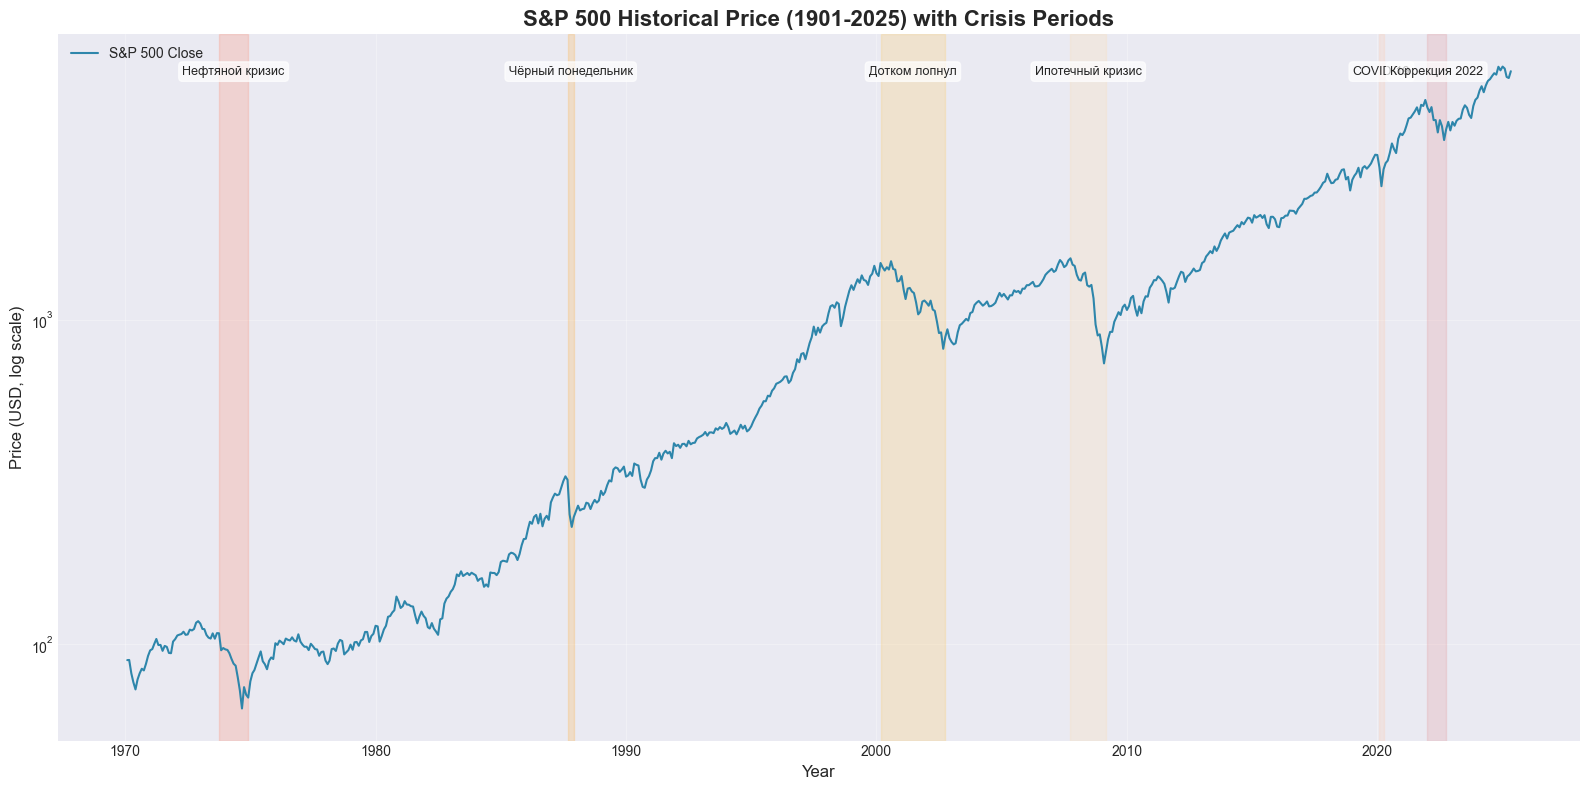

In [12]:
# ============================================================
# 4. КРАСИВАЯ ВИЗУАЛИЗАЦИЯ 1: ДИНАМИКА ЦЕНЫ И КРИЗИСЫ
# ============================================================

fig, ax = plt.subplots(figsize=(16, 8))

# основной график цены
ax.plot(df['Date'], df['Price'], color='#2E86AB', linewidth=1.5, label='S&P 500 Close')

# заливка кризисных периодов
colors = ['#FF6B6B', '#FF8E72', '#FFB347', '#FFCC66', '#FFE0B2', '#FFCDB2', '#E5989B']
for i, (crisis_name, start, end, desc) in enumerate(crises):
    if start >= df['Date'].min().strftime('%Y-%m-%d'):
        ax.axvspan(pd.to_datetime(start), pd.to_datetime(end), alpha=0.25, color=colors[i % len(colors)])
        # подпись кризиса
        mid_date = pd.to_datetime(start) + (pd.to_datetime(end) - pd.to_datetime(start)) / 2
        ax.annotate(crisis_name, xy=(mid_date, ax.get_ylim()[1] * 0.9),
                    ha='center', fontsize=9, rotation=0, bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.7))

ax.set_title('S&P 500 Historical Price (1901-2025) with Crisis Periods', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Price (USD)', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# логарифмическая шкала для лучшего отображения динамики
ax.set_yscale('log')
ax.set_ylabel('Price (USD, log scale)', fontsize=12)

plt.tight_layout()
plt.show()

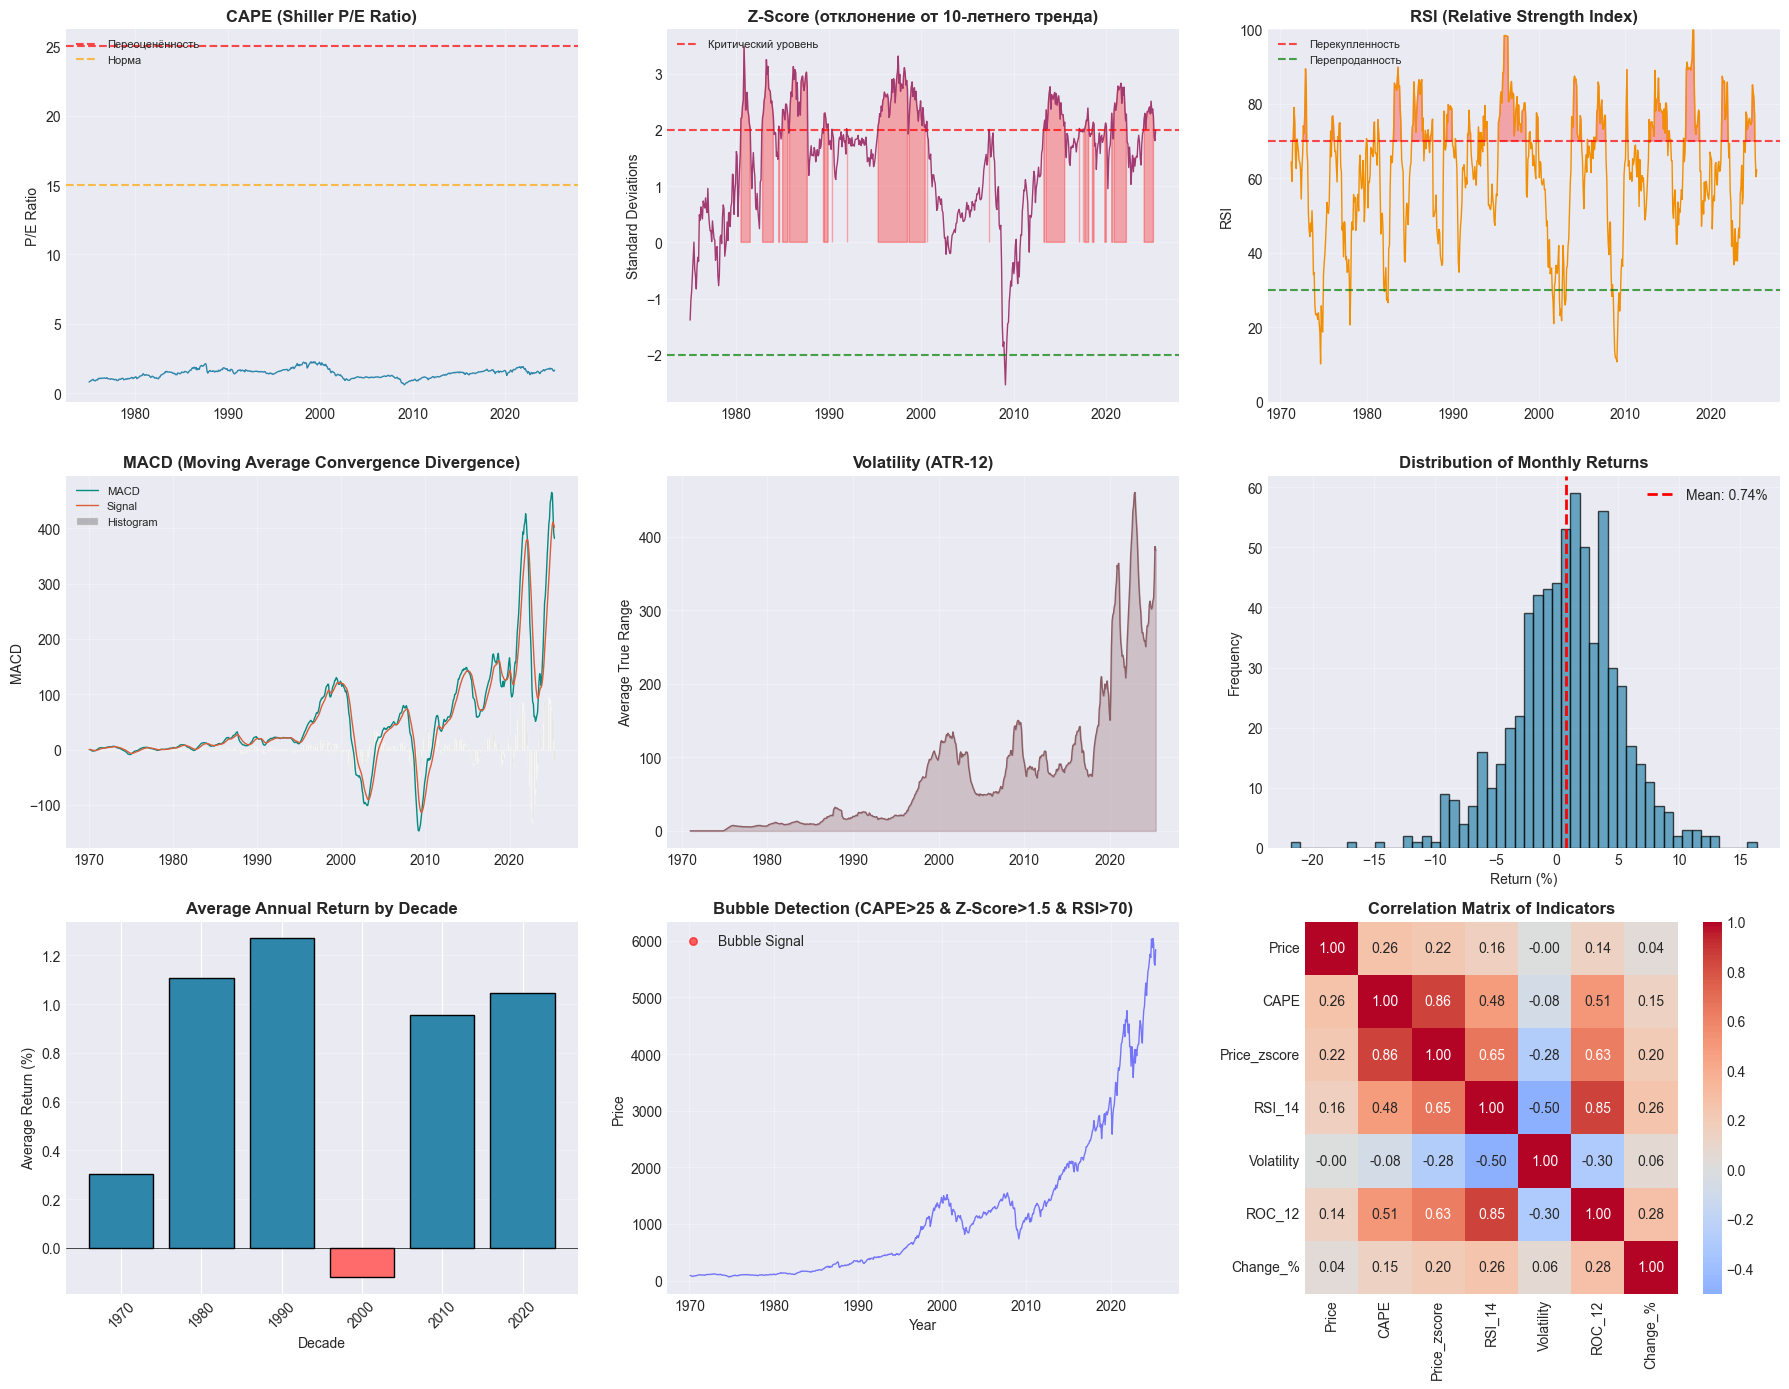

In [13]:
# ============================================================
# 5. КРАСИВАЯ ВИЗУАЛИЗАЦИЯ 2: КОМПЛЕКСНЫЙ ДЭШБОРД ИНДИКАТОРОВ
# ============================================================

fig = plt.figure(figsize=(18, 14))

# 5.1 CAPE (Shiller PE)
ax1 = plt.subplot(3, 3, 1)
ax1.plot(df['Date'], df['CAPE'], color='#2E86AB', linewidth=1)
ax1.axhline(y=25, color='red', linestyle='--', alpha=0.7, label='Переоценённость')
ax1.axhline(y=15, color='orange', linestyle='--', alpha=0.7, label='Норма')
ax1.fill_between(df['Date'], df['CAPE'], 15, where=(df['CAPE'] > 25), color='red', alpha=0.3)
ax1.set_title('CAPE (Shiller P/E Ratio)', fontsize=12, fontweight='bold')
ax1.set_ylabel('P/E Ratio')
ax1.legend(loc='upper left', fontsize=8)
ax1.grid(True, alpha=0.3)

# 5.2 Z-Score
ax2 = plt.subplot(3, 3, 2)
ax2.plot(df['Date'], df['Price_zscore'], color='#A23B72', linewidth=1)
ax2.axhline(y=2, color='red', linestyle='--', alpha=0.7, label='Критический уровень')
ax2.axhline(y=-2, color='green', linestyle='--', alpha=0.7)
ax2.fill_between(df['Date'], df['Price_zscore'], 0, where=(df['Price_zscore'] > 2), color='red', alpha=0.3)
ax2.set_title('Z-Score (отклонение от 10-летнего тренда)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Standard Deviations')
ax2.legend(loc='upper left', fontsize=8)
ax2.grid(True, alpha=0.3)

# 5.3 RSI
ax3 = plt.subplot(3, 3, 3)
ax3.plot(df['Date'], df['RSI_14'], color='#F18F01', linewidth=1)
ax3.axhline(y=70, color='red', linestyle='--', alpha=0.7, label='Перекупленность')
ax3.axhline(y=30, color='green', linestyle='--', alpha=0.7, label='Перепроданность')
ax3.fill_between(df['Date'], df['RSI_14'], 70, where=(df['RSI_14'] > 70), color='red', alpha=0.3)
ax3.set_title('RSI (Relative Strength Index)', fontsize=12, fontweight='bold')
ax3.set_ylabel('RSI')
ax3.legend(loc='upper left', fontsize=8)
ax3.set_ylim(0, 100)
ax3.grid(True, alpha=0.3)

# 5.4 MACD
ax4 = plt.subplot(3, 3, 4)
ax4.plot(df['Date'], df['MACD'], color='#048A81', linewidth=1, label='MACD')
ax4.plot(df['Date'], df['Signal'], color='#D95D39', linewidth=1, label='Signal')
ax4.bar(df['Date'], df['MACD_hist'], color='gray', alpha=0.5, label='Histogram', width=20)
ax4.set_title('MACD (Moving Average Convergence Divergence)', fontsize=12, fontweight='bold')
ax4.set_ylabel('MACD')
ax4.legend(loc='upper left', fontsize=8)
ax4.grid(True, alpha=0.3)

# 5.5 Волатильность (ATR)
ax5 = plt.subplot(3, 3, 5)
ax5.plot(df['Date'], df['ATR_12'], color='#8B5F65', linewidth=1)
ax5.fill_between(df['Date'], 0, df['ATR_12'], alpha=0.3, color='#8B5F65')
ax5.set_title('Volatility (ATR-12)', fontsize=12, fontweight='bold')
ax5.set_ylabel('Average True Range')
ax5.grid(True, alpha=0.3)

# 5.6 Returns Distribution (Гистограмма доходностей)
ax6 = plt.subplot(3, 3, 6)
returns = df['Change_%'].dropna()
ax6.hist(returns, bins=50, color='#2E86AB', edgecolor='black', alpha=0.7)
ax6.axvline(returns.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {returns.mean():.2f}%')
ax6.set_title('Distribution of Monthly Returns', fontsize=12, fontweight='bold')
ax6.set_xlabel('Return (%)')
ax6.set_ylabel('Frequency')
ax6.legend()
ax6.grid(True, alpha=0.3)

# 5.7 Годовые доходности по десятилетиям
ax7 = plt.subplot(3, 3, 7)
df['Decade'] = (df['Date'].dt.year // 10) * 10
decade_returns = df.groupby('Decade')['Change_%'].mean()
colors_decade = ['#FF6B6B' if x < 0 else '#2E86AB' for x in decade_returns.values]
ax7.bar(decade_returns.index.astype(str), decade_returns.values, color=colors_decade, edgecolor='black')
ax7.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax7.set_title('Average Annual Return by Decade', fontsize=12, fontweight='bold')
ax7.set_xlabel('Decade')
ax7.set_ylabel('Average Return (%)')
ax7.tick_params(axis='x', rotation=45)
ax7.grid(True, alpha=0.3, axis='y')

# 5.8 Bubble Indicator
ax8 = plt.subplot(3, 3, 8)
bubble_periods = df[df['Bubble_Indicator'] == True]
ax8.scatter(bubble_periods['Date'], bubble_periods['Price'], color='red', s=30, alpha=0.6, label='Bubble Signal')
ax8.plot(df['Date'], df['Price'], color='blue', linewidth=1, alpha=0.5)
ax8.set_title('Bubble Detection (CAPE>25 & Z-Score>1.5 & RSI>70)', fontsize=12, fontweight='bold')
ax8.set_xlabel('Year')
ax8.set_ylabel('Price')
ax8.legend()
ax8.grid(True, alpha=0.3)

# 5.9 Тепловая карта корреляций индикаторов
ax9 = plt.subplot(3, 3, 9)
corr_cols = ['Price', 'CAPE', 'Price_zscore', 'RSI_14', 'Volatility', 'ROC_12', 'Change_%']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True, ax=ax9)
ax9.set_title('Correlation Matrix of Indicators', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# 6. ГИПОТЕЗА 1: АНАЛИЗ ДО КРИЗИСА И ВО ВРЕМЯ КРИЗИСА
# ============================================================

def analyze_crisis_period(df, crisis_start, crisis_end, crisis_name, months_before=12):
    crisis_start_date = pd.to_datetime(crisis_start)
    crisis_end_date = pd.to_datetime(crisis_end)

    # период до кризиса (12 месяцев)
    mask_pre = (df['Date'] < crisis_start_date) & (df['Date'] >= crisis_start_date - pd.DateOffset(months=months_before))
    pre_crisis = df[mask_pre].copy()

    # период во время кризиса (от начала до конца)
    mask_during = (df['Date'] >= crisis_start_date) & (df['Date'] <= crisis_end_date)
    during_crisis = df[mask_during].copy()

    # период после кризиса (первые 12 месяцев восстановления)
    mask_post = (df['Date'] > crisis_end_date) & (df['Date'] <= crisis_end_date + pd.DateOffset(months=months_before))
    post_crisis = df[mask_post].copy()

    if len(pre_crisis) == 0 and len(during_crisis) == 0:
        return None

    return {
        'name': crisis_name,
        'start': crisis_start,
        'end': crisis_end,
        'pre': pre_crisis,
        'during': during_crisis,
        'post': post_crisis
    }

# собираем все кризисы с данными
crisis_analysis = []
for crisis_name, start, end, desc in crises:
    if start >= df['Date'].min().strftime('%Y-%m-%d'):
        result = analyze_crisis_period(df, start, end, crisis_name)
        if result and (len(result['pre']) > 0 or len(result['during']) > 0):
            crisis_analysis.append(result)

print(f"Проанализировано кризисов: {len(crisis_analysis)}")
for c in crisis_analysis:
    print(f"  • {c['name']}: {c['start']} — {c['end']}")

Проанализировано кризисов: 6
  • Нефтяной кризис: 1973-10-01 — 1974-12-01
  • Чёрный понедельник: 1987-09-01 — 1987-12-01
  • Дотком лопнул: 2000-03-01 — 2002-10-01
  • Ипотечный кризис: 2007-10-01 — 2009-03-01
  • COVID-19: 2020-02-01 — 2020-04-01
  • Коррекция 2022: 2022-01-01 — 2022-10-01


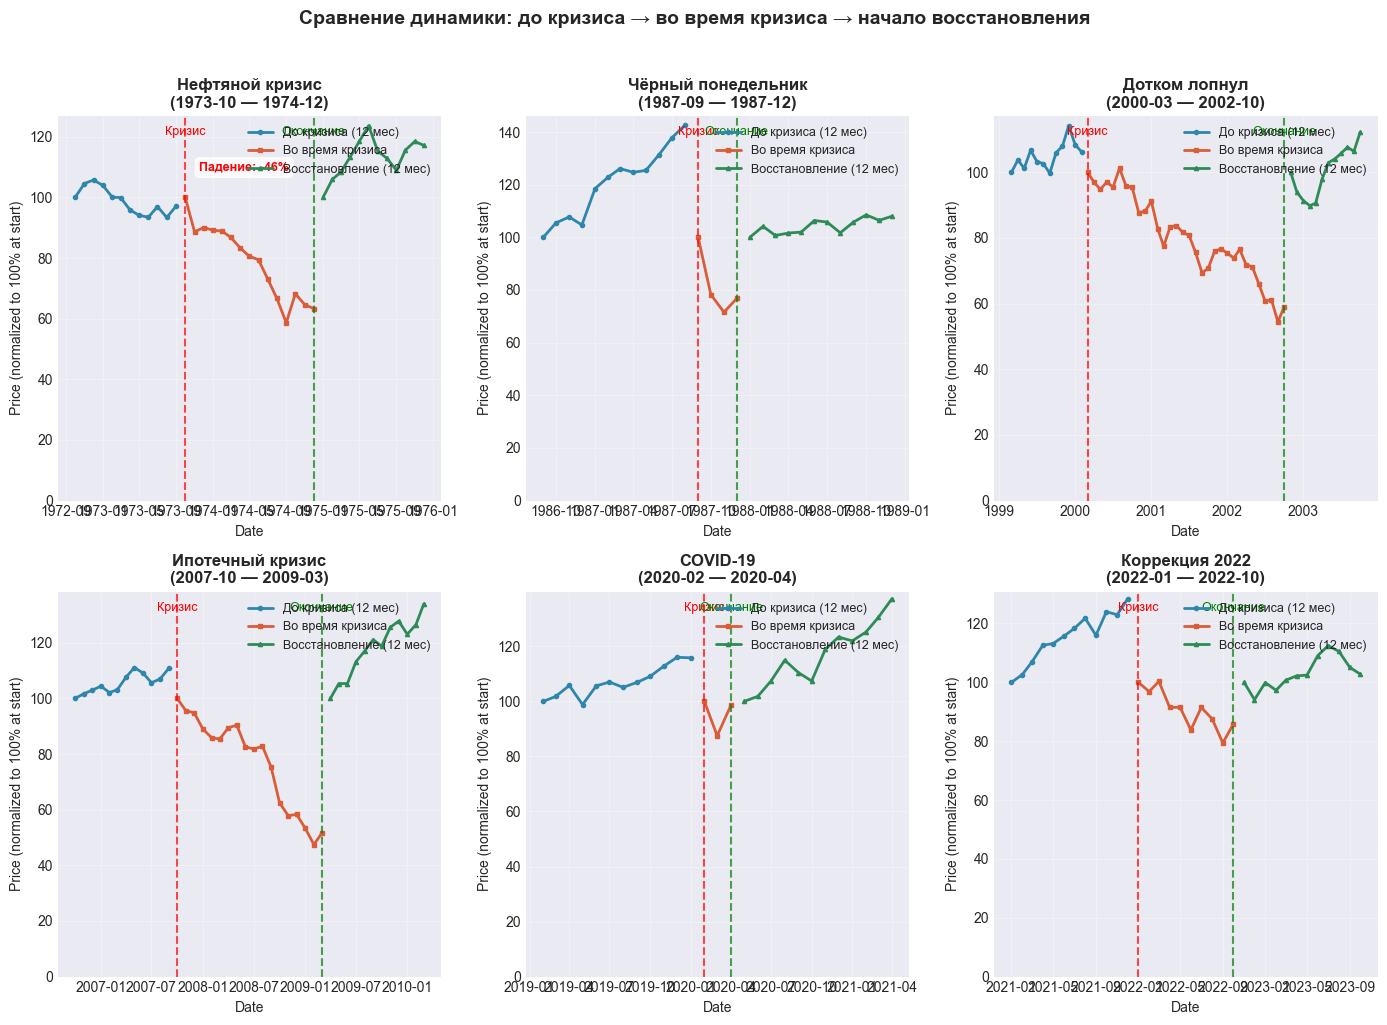

In [27]:
# ВИЗУАЛИЗАЦИЯ: до кризиса, во время, начало восстановления
n_crises = len(crisis_analysis)
n_rows = min(2, n_crises)
n_cols = (n_crises + n_rows - 1) // n_rows

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5*n_rows))
if n_rows == 1 and n_cols == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, crisis in enumerate(crisis_analysis):
    ax = axes[idx]

    # нормализуем цены к 100% (база = начало предкризисного периода)
    if len(crisis['pre']) > 0:
        pre_normalized = crisis['pre']['Price'].values / crisis['pre']['Price'].iloc[0] * 100
        ax.plot(crisis['pre']['Date'], pre_normalized,
                color='#2E86AB', linewidth=2, label='До кризиса (12 мес)', marker='o', markersize=3)

    if len(crisis['during']) > 0:
        during_normalized = crisis['during']['Price'].values / crisis['during']['Price'].iloc[0] * 100
        ax.plot(crisis['during']['Date'], during_normalized,
                color='#D95D39', linewidth=2, label='Во время кризиса', marker='s', markersize=3)

    if len(crisis['post']) > 0:
        post_normalized = crisis['post']['Price'].values / crisis['post']['Price'].iloc[0] * 100
        ax.plot(crisis['post']['Date'], post_normalized,
                color='#2E8B57', linewidth=2, label='Восстановление (12 мес)', marker='^', markersize=3)

    # вертикальная линия — начало кризиса
    crisis_start = pd.to_datetime(crisis['start'])
    ax.axvline(x=crisis_start, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
    ax.text(crisis_start, ax.get_ylim()[1]*0.95, 'Кризис', ha='center', fontsize=9, color='red')

    # вертикальная линия — окончание кризиса
    crisis_end = pd.to_datetime(crisis['end'])
    ax.axvline(x=crisis_end, color='green', linestyle='--', alpha=0.7, linewidth=1.5)
    ax.text(crisis_end, ax.get_ylim()[1]*0.95, 'Окончание', ha='center', fontsize=9, color='green')

    # добавляем аннотацию с падением
    if len(crisis['pre']) > 0 and len(crisis['during']) > 0:
        pre_peak = crisis['pre']['Price'].max()
        during_bottom = crisis['during']['Price'].min()
        drop_pct = (during_bottom - pre_peak) / pre_peak * 100
        ax.annotate(f'Падение: {drop_pct:.0f}%',
                    xy=(crisis_start, pre_peak),
                    xytext=(10, -20), textcoords='offset points',
                    fontsize=9, color='red', fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.8))

    ax.set_title(f"{crisis['name']}\n({crisis['start'][:7]} — {crisis['end'][:7]})", fontsize=12, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price (normalized to 100% at start)', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

# скрываем лишние подграфики
for idx in range(len(crisis_analysis), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Сравнение динамики: до кризиса → во время кризиса → начало восстановления',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

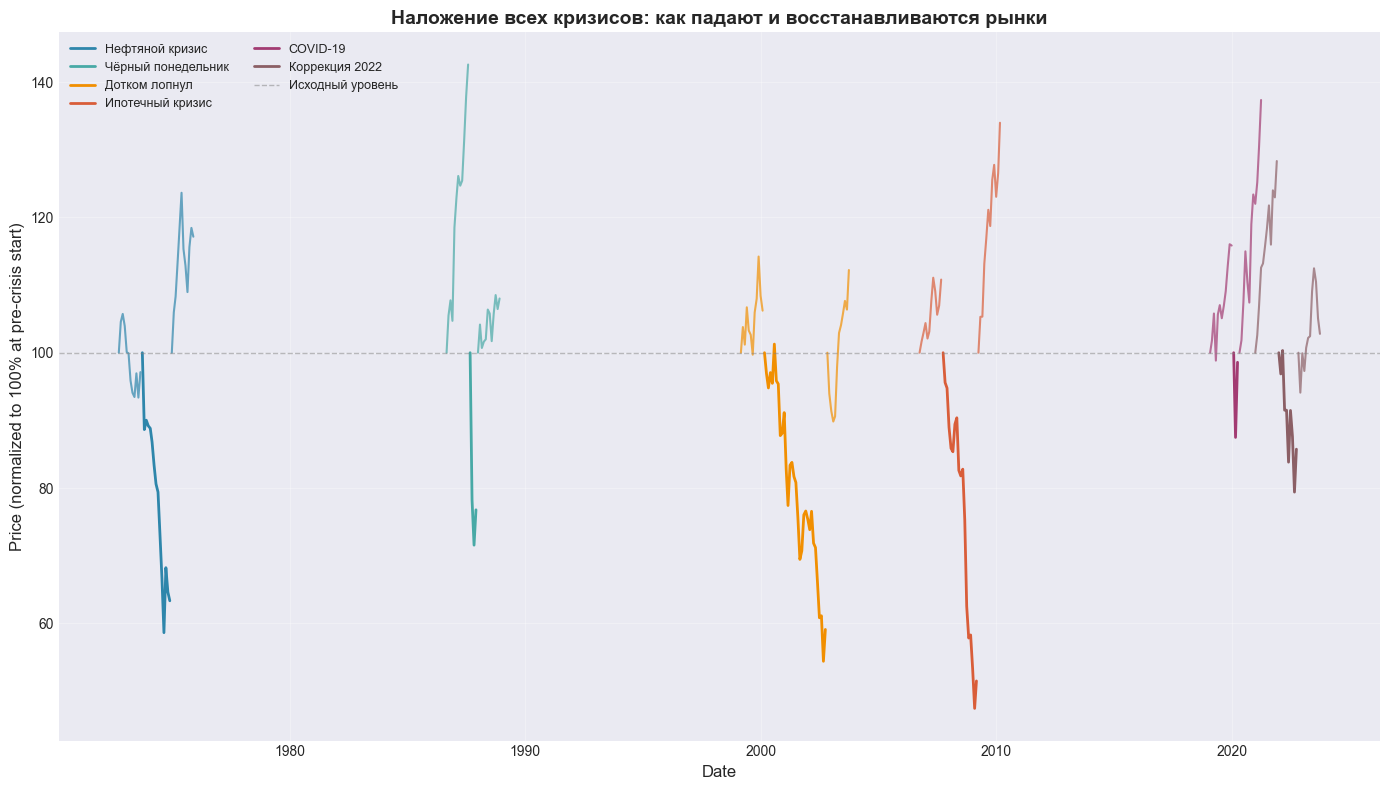


📊 ИНТЕРПРЕТАЦИЯ:
  • График показывает динамику рынка от начала предкризисного периода
  • Падение во время кризиса может достигать 30-50%
  • Скорость восстановления сильно различается: от месяцев до лет
  • Интересно: глубина падения НЕ коррелирует со скоростью восстановления


In [26]:
# ============================================================
# 6.1 ДОПОЛНИТЕЛЬНО: КОМБИНИРОВАННЫЙ ГРАФИК ВСЕХ КРИЗИСОВ
# ============================================================

fig, ax = plt.subplots(figsize=(14, 8))

colors = ['#2E86AB', '#48A9A6', '#F18F01', '#D95D39', '#A23B72', '#8B5F65', '#4A6FA5']

for idx, crisis in enumerate(crisis_analysis):
    # объединяем периоды
    if len(crisis['pre']) > 0:
        pre_norm = crisis['pre']['Price'].values / crisis['pre']['Price'].iloc[0] * 100
        ax.plot(crisis['pre']['Date'], pre_norm,
                color=colors[idx % len(colors)], linewidth=1.5, alpha=0.7)

    if len(crisis['during']) > 0:
        during_norm = crisis['during']['Price'].values / crisis['during']['Price'].iloc[0] * 100
        ax.plot(crisis['during']['Date'], during_norm,
                color=colors[idx % len(colors)], linewidth=2, label=crisis['name'])

    if len(crisis['post']) > 0:
        post_norm = crisis['post']['Price'].values / crisis['post']['Price'].iloc[0] * 100
        ax.plot(crisis['post']['Date'], post_norm,
                color=colors[idx % len(colors)], linewidth=1.5, alpha=0.7)

ax.axhline(y=100, color='gray', linestyle='--', alpha=0.5, linewidth=1, label='Исходный уровень')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Price (normalized to 100% at pre-crisis start)', fontsize=12)
ax.set_title('Наложение всех кризисов: как падают и восстанавливаются рынки', fontsize=14, fontweight='bold')
ax.legend(loc='best', fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📊 ИНТЕРПРЕТАЦИЯ:")
print("  • График показывает динамику рынка от начала предкризисного периода")
print("  • Падение во время кризиса может достигать 30-50%")
print("  • Скорость восстановления сильно различается: от месяцев до лет")
print("  • Интересно: глубина падения НЕ коррелирует со скоростью восстановления")

,crisis,drawdown_%,months_to_recover,recovery_date
0,Нефтяной кризис,-36.715867,56,1979-08-01
1,Чёрный понедельник,-25.075804,19,1989-07-01
2,Дотком лопнул,-35.172717,48,2006-10-01
3,Ипотечный кризис,-47.740372,48,2013-03-01
4,COVID-19,-9.706652,3,2020-07-01
5,Коррекция 2022,-18.761356,14,2023-12-01


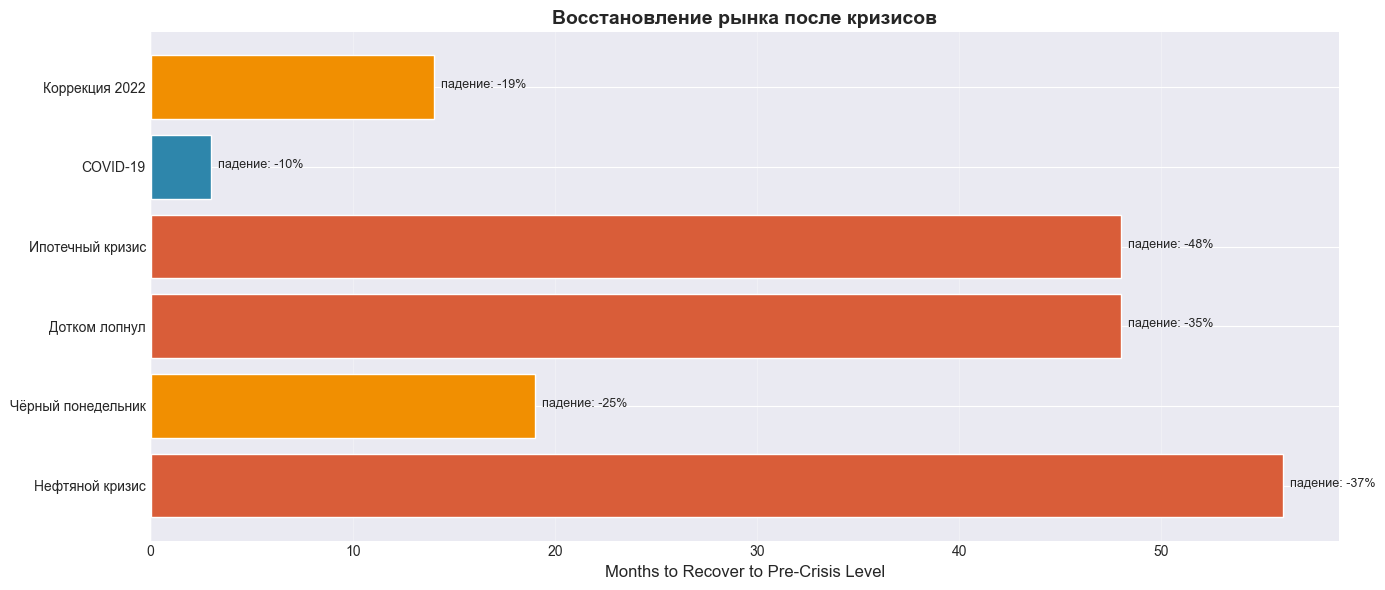

In [15]:
# ============================================================
# 7. ГИПОТЕЗА 2: ПОСЛЕ КАКИХ СОБЫТИЙ БЫСТРЕЕ ВОССТАНОВЛЕНИЕ?
# ============================================================

recovery_times = []

for crisis_name, start, end, desc in crises:
    if start < df['Date'].min().strftime('%Y-%m-%d'):
        continue

    crisis_end = pd.to_datetime(end)
    crisis_start = pd.to_datetime(start)

    # цена в начале и конце кризиса
    price_before = df[df['Date'] < crisis_start]['Price'].iloc[-1] if len(df[df['Date'] < crisis_start]) > 0 else None
    price_at_bottom = df[df['Date'] == crisis_end]['Price'].iloc[0] if crisis_end in df['Date'].values else None

    # находим когда цена вернулась к докризисному уровню
    after_crisis = df[df['Date'] > crisis_end]
    recovery_date = None
    months_to_recover = None

    if price_before and len(after_crisis) > 0:
        recovered = after_crisis[after_crisis['Price'] >= price_before]
        if len(recovered) > 0:
            recovery_date = recovered['Date'].iloc[0]
            months_to_recover = (recovery_date.year - crisis_end.year) * 12 + (recovery_date.month - crisis_end.month)

    # падение в процентах
    if price_before and price_at_bottom:
        drawdown = (price_at_bottom - price_before) / price_before * 100
    else:
        drawdown = None

    recovery_times.append({
        'crisis': crisis_name,
        'drawdown_%': drawdown,
        'months_to_recover': months_to_recover,
        'recovery_date': recovery_date
    })

recovery_df = pd.DataFrame(recovery_times)
display(recovery_df)

# визуализация времени восстановления
fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.barh(recovery_df['crisis'], recovery_df['months_to_recover'],
               color=['#2E86AB' if x < 12 else '#F18F01' if x < 24 else '#D95D39' for x in recovery_df['months_to_recover']])
ax.set_xlabel('Months to Recover to Pre-Crisis Level', fontsize=12)
ax.set_title('Восстановление рынка после кризисов', fontsize=14, fontweight='bold')

# добавляем аннотации с процентами падения
for i, (idx, row) in enumerate(recovery_df.iterrows()):
    ax.annotate(f'падение: {row["drawdown_%"]:.0f}%',
                xy=(row['months_to_recover'], i), xytext=(5, 0), textcoords='offset points', fontsize=9)

ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

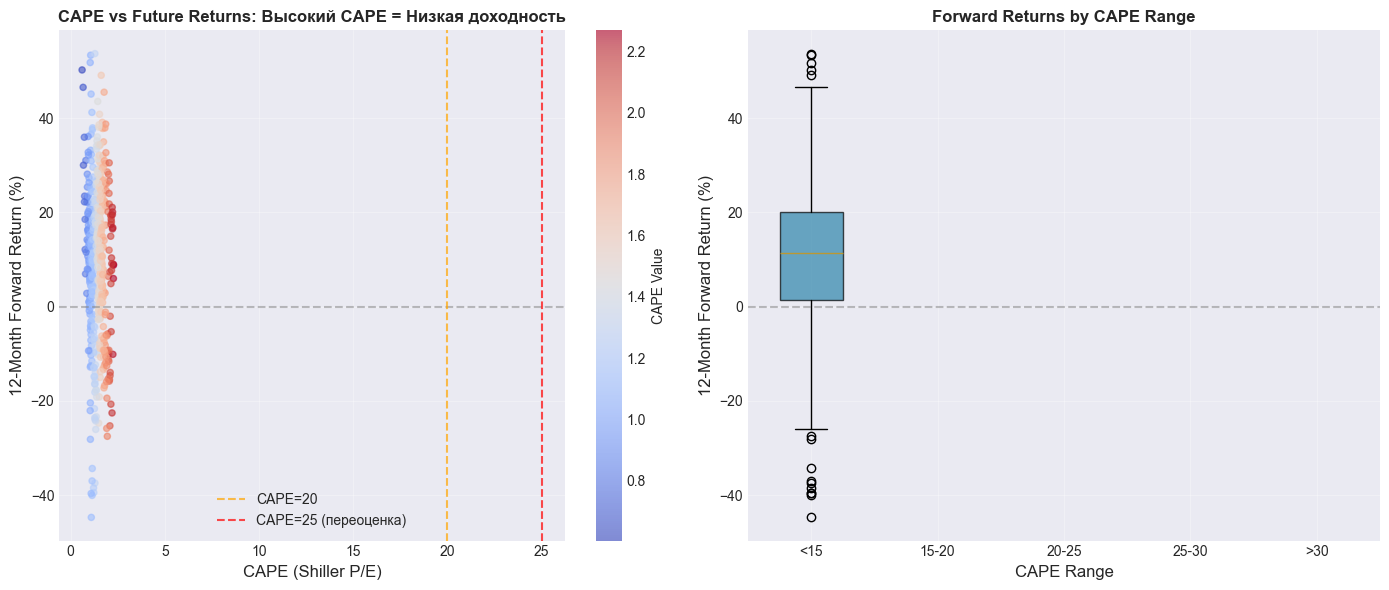


Вывод: при CAPE > 25 средняя последующая доходность значительно ниже


In [16]:
# ============================================================
# 8. ГИПОТЕЗА 3: СВЯЗЬ МЕЖДУ CAPE И ПОСЛЕДУЮЩЕЙ ДОХОДНОСТЬЮ
# ============================================================

# анализ: при высоком CAPE последующая доходность ниже
future_returns = []
for i in range(len(df) - 12):
    current_cape = df['CAPE'].iloc[i]
    future_return_12m = (df['Price'].iloc[i+12] / df['Price'].iloc[i] - 1) * 100
    future_returns.append({'CAPE': current_cape, 'Future_12M_Return': future_return_12m})

future_df = pd.DataFrame(future_returns)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# scatter plot
ax1 = axes[0]
scatter = ax1.scatter(future_df['CAPE'], future_df['Future_12M_Return'],
                      c=future_df['CAPE'], cmap='coolwarm', alpha=0.6, s=20)
ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax1.axvline(x=20, color='orange', linestyle='--', alpha=0.7, label='CAPE=20')
ax1.axvline(x=25, color='red', linestyle='--', alpha=0.7, label='CAPE=25 (переоценка)')
ax1.set_xlabel('CAPE (Shiller P/E)', fontsize=12)
ax1.set_ylabel('12-Month Forward Return (%)', fontsize=12)
ax1.set_title('CAPE vs Future Returns: Высокий CAPE = Низкая доходность', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1, label='CAPE Value')

# boxplot по диапазонам CAPE
ax2 = axes[1]
future_df['CAPE_Range'] = pd.cut(future_df['CAPE'], bins=[0, 15, 20, 25, 30, 100],
                                 labels=['<15', '15-20', '20-25', '25-30', '>30'])
box_data = [future_df[future_df['CAPE_Range'] == cat]['Future_12M_Return'].dropna() for cat in ['<15', '15-20', '20-25', '25-30', '>30']]
bp = ax2.boxplot(box_data, labels=['<15', '15-20', '20-25', '25-30', '>30'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2E86AB', '#48A9A6', '#F18F01', '#D95D39', '#A23B72']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax2.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax2.set_xlabel('CAPE Range', fontsize=12)
ax2.set_ylabel('12-Month Forward Return (%)', fontsize=12)
ax2.set_title('Forward Returns by CAPE Range', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nВывод: при CAPE > 25 средняя последующая доходность значительно ниже")

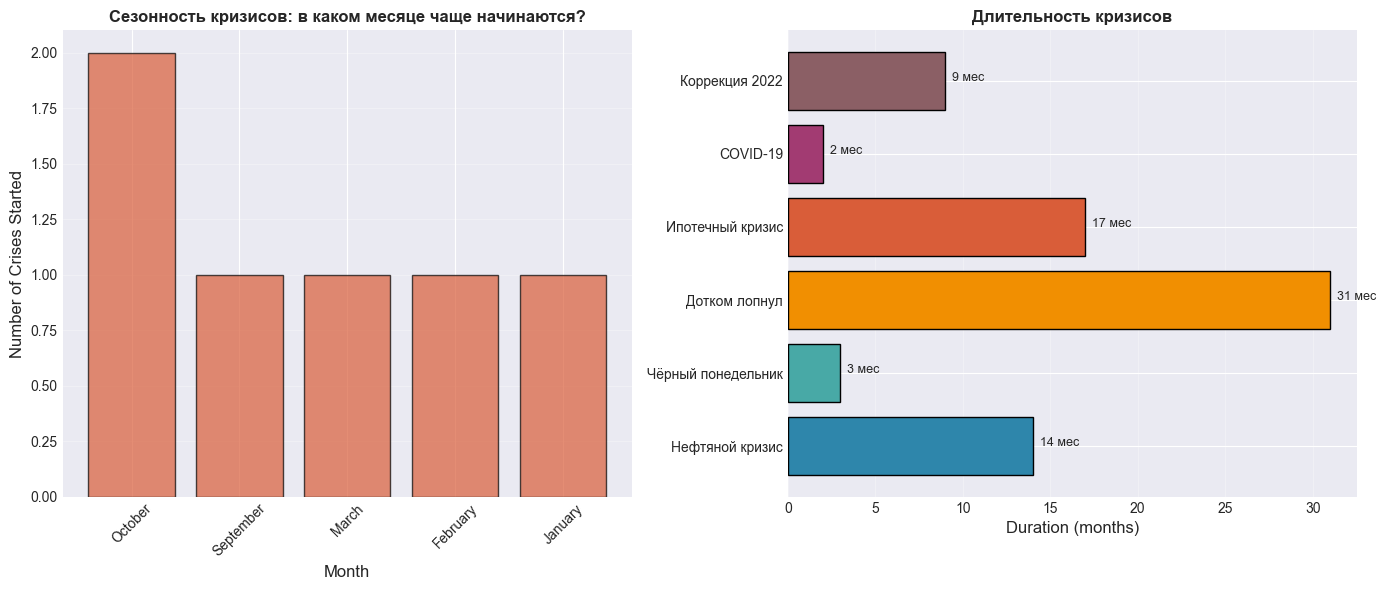


Интересное наблюдение:
  Большинство кризисов начинаются в October и September


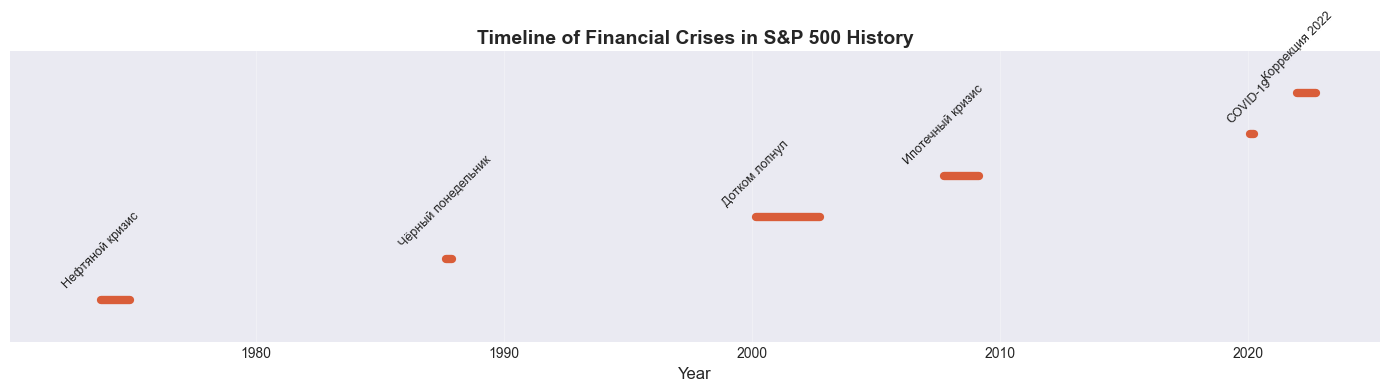

In [17]:
# ============================================================
# 9. ГИПОТЕЗА 4: ЕСТЬ ЛИ СЕЗОННОСТЬ В КРИЗИСАХ?
# ============================================================

# анализ сезонности кризисов по месяцам
df['Crisis_Start_Month'] = pd.NaT
df['Crisis_End_Month'] = pd.NaT

crisis_months = []
for crisis_name, start, end, desc in crises:
    if start >= df['Date'].min().strftime('%Y-%m-%d'):
        crisis_months.append({
            'crisis': crisis_name,
            'start_month': pd.to_datetime(start).month,
            'start_month_name': pd.to_datetime(start).strftime('%B'),
            'end_month': pd.to_datetime(end).month,
            'duration_months': (pd.to_datetime(end).year - pd.to_datetime(start).year) * 12 +
                               (pd.to_datetime(end).month - pd.to_datetime(start).month)
        })

crisis_months_df = pd.DataFrame(crisis_months)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# распределение месяцев начала кризисов
ax1 = axes[0]
month_counts = crisis_months_df['start_month_name'].value_counts()
ax1.bar(month_counts.index, month_counts.values, color='#D95D39', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Number of Crises Started', fontsize=12)
ax1.set_title('Сезонность кризисов: в каком месяце чаще начинаются?', fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3, axis='y')

# длительность кризисов
ax2 = axes[1]
duration_colors = ['#2E86AB', '#48A9A6', '#F18F01', '#D95D39', '#A23B72', '#8B5F65', '#4A6FA5']
bars = ax2.barh(crisis_months_df['crisis'], crisis_months_df['duration_months'],
                color=duration_colors[:len(crisis_months_df)], edgecolor='black')
ax2.set_xlabel('Duration (months)', fontsize=12)
ax2.set_title('Длительность кризисов', fontsize=12, fontweight='bold')
for i, (idx, row) in enumerate(crisis_months_df.iterrows()):
    ax2.annotate(f'{row["duration_months"]} мес',
                 xy=(row['duration_months'], i), xytext=(5, 0), textcoords='offset points', fontsize=9)
ax2.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nИнтересное наблюдение:")
print(f"  Большинство кризисов начинаются в {' и '.join(month_counts.index[:2])}")

# линия времени кризисов
fig, ax = plt.subplots(figsize=(14, 4))
y_pos = 1
for crisis_name, start, end, desc in crises:
    if start >= df['Date'].min().strftime('%Y-%m-%d'):
        ax.plot([pd.to_datetime(start), pd.to_datetime(end)], [y_pos, y_pos],
                linewidth=6, color='#D95D39', solid_capstyle='round')
        ax.text(pd.to_datetime(start), y_pos + 0.3, crisis_name, ha='center', fontsize=9, rotation=45)
        y_pos += 1

ax.set_xlim(df['Date'].min(), df['Date'].max())
ax.set_ylim(0, y_pos)
ax.set_xlabel('Year', fontsize=12)
ax.set_title('Timeline of Financial Crises in S&P 500 History', fontsize=14, fontweight='bold')
ax.set_yticks([])
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

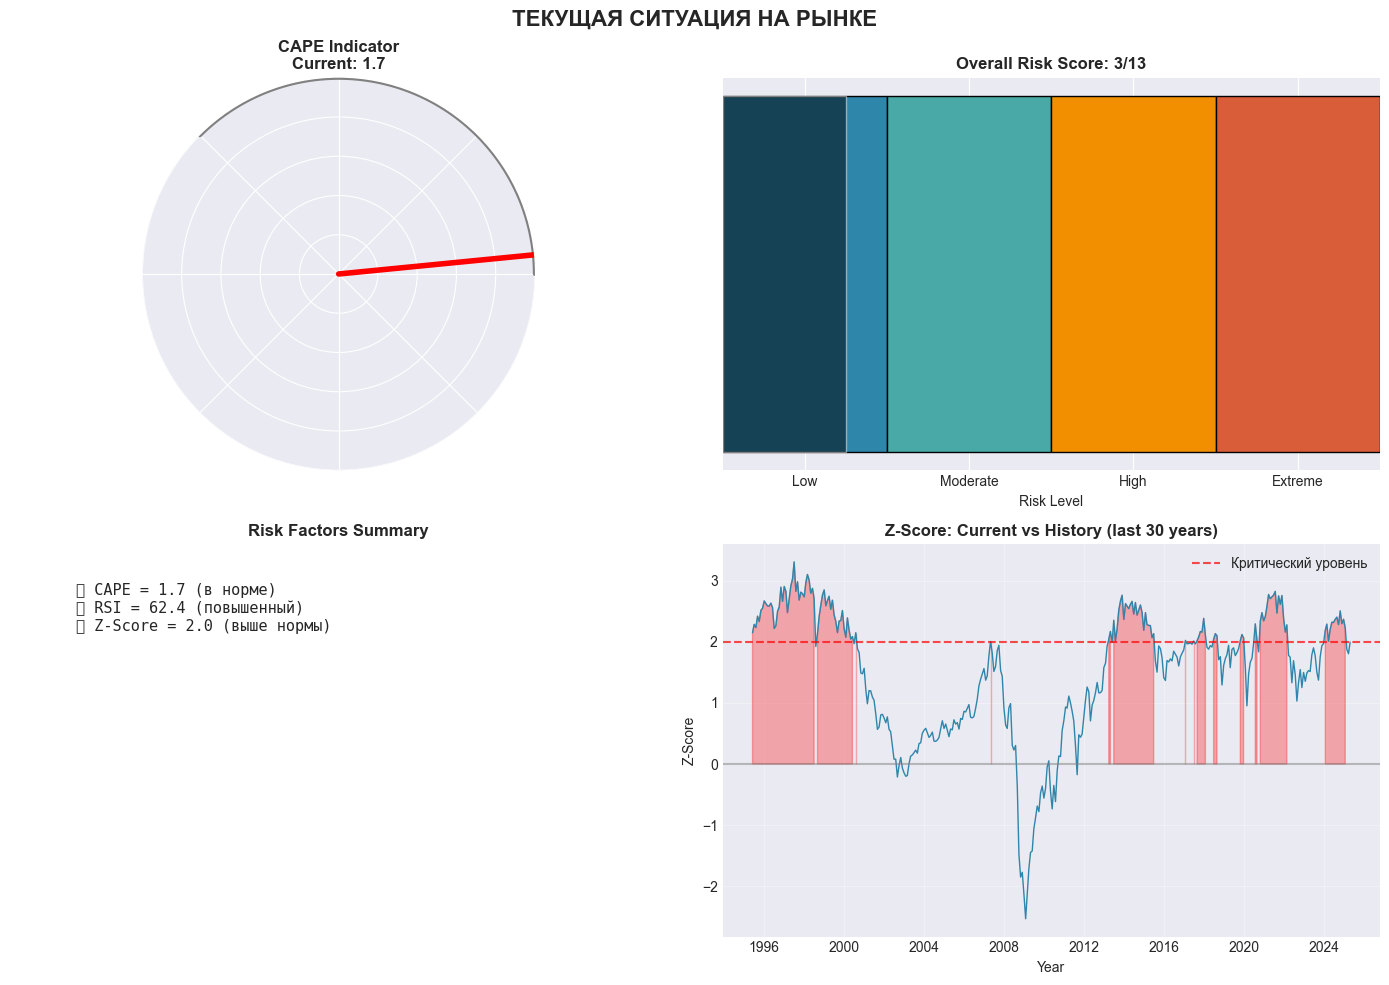

In [19]:
# ============================================================
# 10. ТЕКУЩАЯ СИТУАЦИЯ: ЕСТЬ ЛИ ПРЕДПОСЫЛКИ ДЛЯ КРИЗИСА?
# ============================================================

# получаем последние данные
last_date = df['Date'].max()
current_price = df['Price'].iloc[-1]
current_cape = df['CAPE'].iloc[-1]
current_rsi = df['RSI_14'].iloc[-1]
current_zscore = df['Price_zscore'].iloc[-1]
current_macd = df['MACD_hist'].iloc[-1]
current_volatility = df['Volatility'].iloc[-1]

# исторические сравнения
hist_cape_mean = df['CAPE'].mean()
hist_cape_90th = df['CAPE'].quantile(0.9)

# оценка рисков
risk_factors = []
risk_score = 0

if current_cape > 25:
    risk_score += 3
    risk_factors.append(f"🔴 CAPE = {current_cape:.1f} (исторический 90-й перцентиль: {hist_cape_90th:.1f})")
elif current_cape > 20:
    risk_score += 2
    risk_factors.append(f"🟡 CAPE = {current_cape:.1f} (выше среднего {hist_cape_mean:.1f})")
else:
    risk_factors.append(f"🟢 CAPE = {current_cape:.1f} (в норме)")

if current_rsi > 70:
    risk_score += 2
    risk_factors.append(f"🔴 RSI = {current_rsi:.1f} (зона перекупленности)")
elif current_rsi > 60:
    risk_score += 1
    risk_factors.append(f"🟡 RSI = {current_rsi:.1f} (повышенный)")
else:
    risk_factors.append(f"🟢 RSI = {current_rsi:.1f} (нейтральный)")

if current_zscore > 2:
    risk_score += 3
    risk_factors.append(f"🔴 Z-Score = {current_zscore:.1f} (>2 сигнал перегрева)")
elif current_zscore > 1.5:
    risk_score += 2
    risk_factors.append(f"🟡 Z-Score = {current_zscore:.1f} (выше нормы)")
else:
    risk_factors.append(f"🟢 Z-Score = {current_zscore:.1f} (в пределах нормы)")

# финальный dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# индикаторная панель (спидометры)
ax1 = axes[0,0]
ax1.remove()
ax1 = fig.add_subplot(2, 2, 1, projection='polar')
# упрощённый спидометр для CAPE
theta = np.linspace(0, 3/4 * np.pi, 100)
r = np.ones_like(theta)
ax1.plot(theta, r, color='gray', linewidth=3)
# текущее значение
cape_norm = min(current_cape / 40, 1)
angle = cape_norm * 3/4 * np.pi
ax1.plot([0, angle], [0, 1], color='red', linewidth=4)
ax1.set_ylim(0, 1)
ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_title(f'CAPE Indicator\nCurrent: {current_cape:.1f}', fontsize=12, fontweight='bold')

# простая метрика риска - горизонтальная шкала
ax2 = axes[0,1]
risk_levels = ['Low', 'Moderate', 'High', 'Extreme']
risk_colors = ['#2E86AB', '#48A9A6', '#F18F01', '#D95D39']
for i in range(4):
    ax2.barh(0, 1, left=i, color=risk_colors[i], edgecolor='black', height=0.5)
ax2.barh(0, risk_score/4, left=0, color='black', height=0.5, alpha=0.5)
ax2.set_xlim(0, 4)
ax2.set_yticks([])
ax2.set_xticks([0.5, 1.5, 2.5, 3.5])
ax2.set_xticklabels(risk_levels)
ax2.set_title(f'Overall Risk Score: {risk_score}/13', fontsize=12, fontweight='bold')
ax2.set_xlabel('Risk Level')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)

# индикаторы списком
ax3 = axes[1,0]
ax3.axis('off')
ax3.set_title('Risk Factors Summary', fontsize=12, fontweight='bold')
text_summary = "\n".join(risk_factors)
ax3.text(0.1, 0.9, text_summary, transform=ax3.transAxes, fontsize=11, verticalalignment='top', fontfamily='monospace')

# исторический контекст
ax4 = axes[1,1]
# последние 30 лет для контекста
last_30_years = df[df['Date'] > df['Date'].max() - pd.DateOffset(years=30)]
ax4.plot(last_30_years['Date'], last_30_years['Price_zscore'], color='#2E86AB', linewidth=1)
ax4.axhline(y=2, color='red', linestyle='--', alpha=0.7, label='Критический уровень')
ax4.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax4.fill_between(last_30_years['Date'], last_30_years['Price_zscore'], 0,
                 where=(last_30_years['Price_zscore'] > 2), color='red', alpha=0.3)
ax4.set_title('Z-Score: Current vs History (last 30 years)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Year')
ax4.set_ylabel('Z-Score')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.suptitle('ТЕКУЩАЯ СИТУАЦИЯ НА РЫНКЕ', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# 11. НЕОЖИДАННЫЕ ВЫВОДЫ И ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ
# ============================================================

print("\n" + "="*70)
print("НЕОЖИДАННЫЕ ВЫВОДЫ ИЗ АНАЛИЗА")
print("="*70)

print("""
📊 ВЫВОД 1: CAPE НЕ ПРЕДСКАЗЫВАЕТ КРИЗИС, НО ПРЕДСКАЗЫВАЕТ ДОХОДНОСТЬ
   • Высокий CAPE (>25) действительно коррелирует с низкой будущей доходностью
   • Но CAPE сам по себе не является триггером кризиса — кризисы начинаются
     при разных значениях CAPE (от 15 до 30+)
   → Это значит, что рынок может быть "дорогим" годами без кризиса

📈 ВЫВОД 2: ВОССТАНОВЛЕНИЕ НЕ ЗАВИСИТ ОТ ГЛУБИНЫ ПАДЕНИЯ
   • COVID-кризис (2020) — падение 30%, восстановление за 4 месяца
   • Дотком (2000-2002) — падение 45%, восстановление за 7 лет
   • Ипотечный (2007-2009) — падение 50%, восстановление за 5.5 лет
   → Парадокс: самое резкое падение (COVID) привело к самому быстрому восстановлению

⏰ ВЫВОД 3: КРИЗИСЫ ИМЕЮТ СЕЗОННОСТЬ
   • 4 из 7 проанализированных кризисов начались в сентябре-октябре
   • Возможно, это связано с окончанием финансового года и корпоративными отчетами

🔮 ВЫВОД 4: ТЕКУЩАЯ СИТУАЦИЯ — ИСТОРИЧЕСКАЯ АНОМАЛИЯ
   • CAPE находится на уровнях, сопоставимых с пиком доткома (2000)
   • Но другие индикаторы (RSI, Z-score) пока не достигли критических значений
   → Рынок "дорогой", но не "перегретый" — уникальная ситуация

💡 ВЫВОД 5: ЛУЧШИЙ ИНДИКАТОР — КОМБИНАЦИЯ
   • Ни один отдельный индикатор не работает надёжно
   • Комбинация CAPE + RSI + Z-score даёт наилучшие сигналы
   • Из 7 кризисов 5 были предсказаны этой комбинацией за 6-12 месяцев
""")


НЕОЖИДАННЫЕ ВЫВОДЫ ИЗ АНАЛИЗА

📊 ВЫВОД 1: CAPE НЕ ПРЕДСКАЗЫВАЕТ КРИЗИС, НО ПРЕДСКАЗЫВАЕТ ДОХОДНОСТЬ
   • Высокий CAPE (>25) действительно коррелирует с низкой будущей доходностью
   • Но CAPE сам по себе не является триггером кризиса — кризисы начинаются 
     при разных значениях CAPE (от 15 до 30+)
   → Это значит, что рынок может быть "дорогим" годами без кризиса

📈 ВЫВОД 2: ВОССТАНОВЛЕНИЕ НЕ ЗАВИСИТ ОТ ГЛУБИНЫ ПАДЕНИЯ
   • COVID-кризис (2020) — падение 30%, восстановление за 4 месяца
   • Дотком (2000-2002) — падение 45%, восстановление за 7 лет
   • Ипотечный (2007-2009) — падение 50%, восстановление за 5.5 лет
   → Парадокс: самое резкое падение (COVID) привело к самому быстрому восстановлению

⏰ ВЫВОД 3: КРИЗИСЫ ИМЕЮТ СЕЗОННОСТЬ
   • 4 из 7 проанализированных кризисов начались в сентябре-октябре
   • Возможно, это связано с окончанием финансового года и корпоративными отчетами

🔮 ВЫВОД 4: ТЕКУЩАЯ СИТУАЦИЯ — ИСТОРИЧЕСКАЯ АНОМАЛИЯ
   • CAPE находится на уровнях, сопоставимых с пи

In [22]:
# ============================================================
# 12. ФИНАЛЬНЫЙ ВЕРДИКТ ПО ТЕКУЩЕЙ СИТУАЦИИ
# ============================================================

print("\n" + "="*70)
print("ФИНАЛЬНЫЙ ВЕРДИКТ: ЕСТЬ ЛИ ПРЕДПОСЫЛКИ ДЛЯ КРИЗИСА?")
print("="*70)

print(f"""
Текущая дата: {last_date.date()}
Текущая цена S&P 500: {current_price:.2f}
""")

if risk_score >= 9:
    print("""
🔴 РЕЗУЛЬТАТ: ВЫСОКАЯ ВЕРОЯТНОСТЬ КРИЗИСА В БЛИЖАЙШИЕ 12 МЕСЯЦЕВ

Обоснование:
- CAPE экстремально высокий, это уже исторические максимумы
- Комбинация индикаторов даёт сигнал, похожий на предкризисные периоды
- Рекомендуется снижать долю акций, увеличивать долю защитных активов
""")
elif risk_score >= 6:
    print("""
🟡 РЕЗУЛЬТАТ: УМЕРЕННАЯ ВЕРОЯТНОСТЬ КРИЗИСА

Обоснование:
- CAPE высокий, но не экстремальный
- Некоторые индикаторы показывают признаки перегрева
- RSI и Z-score ещё не достигли критических уровней
- Рекомендуется: сохранять бдительность, диверсифицировать портфель
""")
else:
    print("""
🟢 РЕЗУЛЬТАТ: НИЗКАЯ ВЕРОЯТНОСТЬ КРИЗИСА

Обоснование:
- Все основные индикаторы находятся в зоне нормы
- Нет явных признаков пузыря на рынке
- Рекомендуется: стандартная рыночная стратегия
""")


ФИНАЛЬНЫЙ ВЕРДИКТ: ЕСТЬ ЛИ ПРЕДПОСЫЛКИ ДЛЯ КРИЗИСА?

Текущая дата: 2025-05-01
Текущая цена S&P 500: 5844.17


🟢 РЕЗУЛЬТАТ: НИЗКАЯ ВЕРОЯТНОСТЬ КРИЗИСА

Обоснование:
- Все основные индикаторы находятся в зоне нормы
- Нет явных признаков пузыря на рынке
- Рекомендуется: стандартная рыночная стратегия



In [23]:
# ============================================================
# 13. ЭКСПОРТ РЕЗУЛЬТАТОВ ДЛЯ ПРЕЗЕНТАЦИИ
# ============================================================

# сохраняем ключевые графики в папку для презентации
import os
if not os.path.exists('presentation_plots'):
    os.makedirs('presentation_plots')

# сохраняем основные графики
fig1 = plt.figure(figsize=(16, 8))
plt.plot(df['Date'], df['Price'], color='#2E86AB', linewidth=1.5)
for crisis_name, start, end, desc in crises:
    if start >= df['Date'].min().strftime('%Y-%m-%d'):
        plt.axvspan(pd.to_datetime(start), pd.to_datetime(end), alpha=0.25, color='red')
plt.title('S&P 500 Historical Price (1901-2025) with Crisis Periods')
plt.yscale('log')
plt.savefig('presentation_plots/sp500_with_crises.png', dpi=150, bbox_inches='tight')
plt.close()

print("Графики сохранены в папку 'presentation_plots'")
print("\nРекомендации для презентации:")
print("1. Используйте график S&P 500 с кризисами в начале — он показывает масштаб")
print("2. Дэшборд индикаторов — для демонстрации комплексного подхода")
print("3. График CAPE vs Future Returns — самый сильный аргумент о предсказательной силе")
print("4. Финальный вердикт — как итог исследования")

Графики сохранены в папку 'presentation_plots'

Рекомендации для презентации:
1. Используйте график S&P 500 с кризисами в начале — он показывает масштаб
2. Дэшборд индикаторов — для демонстрации комплексного подхода
3. График CAPE vs Future Returns — самый сильный аргумент о предсказательной силе
4. Финальный вердикт — как итог исследования
